

# Bayes Rule and Bayes Classification

This assignment is broken up into two main sections
1. Naive Bayes Classification Walkthrough
2. Exercises

In the first section, please read through the text and run the code to follow through how we can use Python/Pandas to build Bayes models. In the second section, you are asked to complete two exercises using Bayes to build machine learning models.



## Naive Bayes Classification Walkthrough

*Classification* is one form of supervised learning. The aim is to annotate all data points with a label. Those points that have the same label belong to the same class. There can be two or more labels. For example, a lifeform can be classified (coarsely) with labels animal, plant, fungi, archaea, bacteria, protozoa, and chromista. The data points are observed to have certain features that can be used to predict their labels. For example, if it is has feathers, then it is most likely an animal.

In supervised learning an algorithm is first given a training set of data points with their features and labels. Then the algorithm learns from these features and labels a (probabilistic) model, which can afterwards be used to predict the labels of previously unseen data.

*Naive Bayes classification* is a fast and simple to understand classification method. Its speed is due to some simplifications we make about the underlying probability distributions, namely, the assumption about the independence of features. Yet, it can be quite powerful, especially when there are enough features in the data.

Suppose we have for each label L a probability distribution. This distribution gives probability for each possible combination of features (a feature vector):

$$P(features | L).$$

The main idea in Bayesian classification is to reverse the direction of dependence: we want to predict the label based on the features:

$$P(L | features)$$

This is possible by [the Bayes theorem](https://en.wikipedia.org/wiki/Bayes%27_theorem):

$$P(L | features) = \frac{P(features | L)P(L)}{P(features)}.$$

Let's assume we have to labels L1 and L2, and their associated distributions: $P(features | L1)$ and $P(features | L2)$. If we have a data point with "features", whose label we don't know, we can try to predict it using the ratio of posterior probabilities:

$$\frac{P(L1 | features)}{P(L2 | features)} = \frac{P(features | L1)P(L1)}{P(features | L2)P(L2)}.$$

If the ratio is greater than one, we label our data point with label L1, and if not, we give it label L2.
The prior probabilities P(L1) and P(L2) of labels can be easily found out from the input data, as for each data point we also have its label. Same goes for the probabilities of features conditioned on the label.

We first demonstrate naive Bayes classification using Gaussian distributions.

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

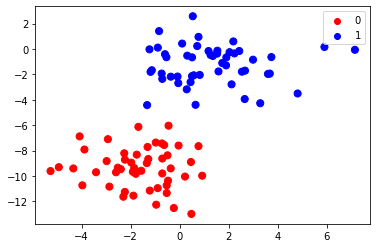

In [ ]:
from sklearn.datasets import make_blobs
X,y = make_blobs(100, 2, centers=2, random_state=2, cluster_std=1.5)
colors=np.array(["red", "blue"])
plt.scatter(X[:, 0], X[:, 1], c=colors[y], s=50)
for label, c in enumerate(colors):
    plt.scatter([], [], c=c, label=str(label))
plt.legend();
#plt.colorbar();

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
model = GaussianNB()
#model = MultinomialNB()
model.fit(X, y);

Naive Bayes algorithm fitted two 2-dimensional Gaussian distribution to the data. The means and the variances define these distributions completely.

In [ ]:
print("Means:", model.theta_)
print("Standard deviations:", model.sigma_)

Means: [[-1.64939095 -9.36891451]
 [ 1.29327924 -1.24101221]]
Standard deviations: [[2.06097005 2.47716872]
 [3.33164807 2.22401384]]


Let's plot these distributions. First we define a helper function to draw an ellipse that gives the standard deviation in each direction from the origo.

In [ ]:
def plot_ellipse(ax, mu, sigma, color="k", label=None):
    """
    Based on
    http://stackoverflow.com/questions/17952171/not-sure-how-to-fit-data-with-a-gaussian-python.
    """
    from matplotlib.patches import Ellipse
    # Compute eigenvalues and associated eigenvectors
    vals, vecs = np.linalg.eigh(sigma)

    # Compute "tilt" of ellipse using first eigenvector
    x, y = vecs[:, 0]
    theta = np.degrees(np.arctan2(y, x))

    # Eigenvalues give length of ellipse along each eigenvector
    w, h = 2 * np.sqrt(vals)

    ax.tick_params(axis='both', which='major', labelsize=20)
    ellipse = Ellipse(mu, w, h, theta, color=color, label=label)  # color="k")
    ellipse.set_clip_box(ax.bbox)
    ellipse.set_alpha(0.2)
    ax.add_artist(ellipse)
    return ellipse

Then we do the actual plotting:

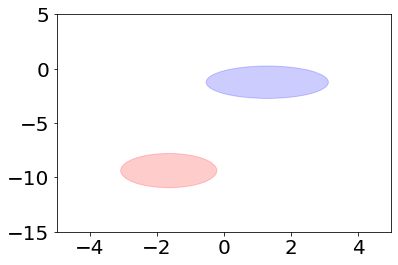

In [ ]:
plt.figure()
plt.xlim(-5, 5)
plt.ylim(-15, 5)
plot_ellipse(plt.gca(), model.theta_[0], np.identity(2)*model.sigma_[0], color="red")
plot_ellipse(plt.gca(), model.theta_[1], np.identity(2)*model.sigma_[1], color="blue");

*Accuracy score* gives a measure about how well we managed to predict the labels. The maximum value is 1.0.

In [ ]:
from sklearn.metrics import accuracy_score
y_fitted = model.predict(X)
acc=accuracy_score(y,y_fitted)
print("Accuracy score is", acc)

Accuracy score is 1.0


The score was the best possible, which is not a surprise, since we tried to predict the data we had already seen! Later we will split our data into two parts: one for learning the model and the other for testing its predictive skills.

## [Question - Accuracy]
What is a situation when the accuracy score is not a good representation of the quality of a classification?

### Another example

Let's generate some more data using multivariate normal distributions.

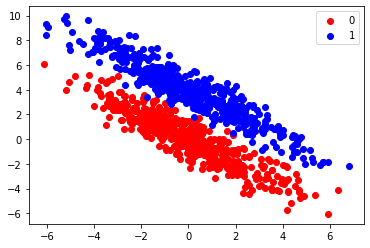

In [ ]:
cov=np.array([[ 4.68, -4.32],
 [-4.32,  4.68]])
mean1 = [0,0]
mean2 = [0,4]
n=500
x1 = np.random.multivariate_normal(mean1, cov, n).T
x2 = np.random.multivariate_normal(mean2, cov, n).T
X=np.vstack([x1.T,x2.T])
y=np.hstack([[0]*n, [1]*n]).T
plt.scatter(X[:n,0], X[:n,1], color="red", label=0)
plt.scatter(X[n:,0], X[n:,1], color="blue", label=1)
plt.legend();

The two clusters seem to be quite separate. Let's try naive Bayesian classification on this data.

In [ ]:
model = GaussianNB()
#model = MultinomialNB()
model.fit(X, y);

In [ ]:
print("Means:", model.theta_)
print("Standard deviations:", model.sigma_)

Means: [[3.71349120e-02 4.32365684e-04]
 [6.50099652e-02 3.95970949e+00]]
Standard deviations: [[4.29938312 4.39258824]
 [5.14910217 5.21349433]]


Accuracy score is 0.825


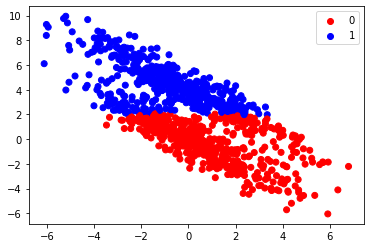

In [ ]:
y_fitted = model.predict(X)
colors=np.array(["red", "blue"])
plt.scatter(X[:,0], X[:,1], color=colors[y_fitted])
plt.scatter([], [], color="red", label="0")
plt.scatter([], [], color="blue", label="1")
from sklearn.metrics import accuracy_score
acc=accuracy_score(y,y_fitted)
plt.legend()
print("Accuracy score is", acc)

Even thought the score is quite good, we can see from the plot that the algorithm didn't have good models for the data. We can plot the models the algorithm used:

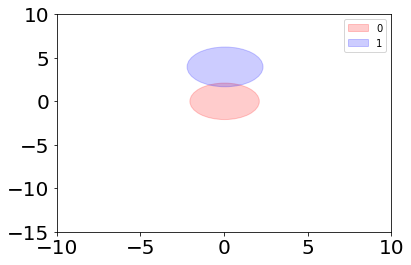

In [ ]:
plt.figure()
plt.xlim(-10, 10)
plt.ylim(-15, 10)
e1=plot_ellipse(plt.gca(), model.theta_[0], np.identity(2)*model.sigma_[0], color="red", label="0")
e2=plot_ellipse(plt.gca(), model.theta_[1], np.identity(2)*model.sigma_[1], color="blue", label="1")
plt.legend([e1, e2], ["0", "1"]);

The problem with naive Bayesian classification is that it tries to model the data using Gaussian distributions, which are aligned along the x and y axes. With this example data we would have needed Gaussian distributions which are "tilted".

### Text classification

We next try to classify a set of messages that were posted on a public forum. The messages were divided into groups by the topics. So, we have a data set ready for classification testing. Let's first load this data using scikit-learn and print the message categories.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
data = fetch_20newsgroups()
data.target_names

['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

We concentrate on four message categories only. The tool `fetch_20newsgroups` allows us to easily split the data into training and testing data.

In [ ]:
categories = ['comp.graphics', 'rec.autos', 'sci.electronics', 'sci.crypt']
train = fetch_20newsgroups(subset='train', categories=categories)
test = fetch_20newsgroups(subset='test', categories=categories)

Let's see what we got:

In [ ]:
print("Training data:", "Data:", str(type(train.data)), len(train.data), "Target:", str(type(train.target)), len(train.target))
print("Test data:", "Data:", str(type(test.data)), len(test.data), "Target", str(type(test.data)), len(test.target))

Training data: Data: <class 'list'> 2364 Target: <class 'numpy.ndarray'> 2364
Test data: Data: <class 'list'> 1574 Target <class 'list'> 1574


We use as features the frequencies of each word in the dataset. That is, there are as many features as there are distinct words in the dataset. We denote the number of features by $f$. As the features are now counts, it is sensible to use multinomial distribution instead of Gaussian. 

Let's try to model these messages using multinomial distributions. Each message category has its own distribution. A multinomial distribution has $f$ non-negative parameters $\theta_1,\ldots , \theta_f$, which sum up to one. For example, the parameter $\theta_3$ might tell the the probability of the word "board" appearing in a message of the category this distribution is describing.

In scikit-learn there is a class `CountVectorizer` that converts messages in form of text strings to feature vectors. We can integrate this conversion with the model we are using (multinomial naive Bayes), so that the conversion happens automatically as part of the `fit` method. We achive this integration using the `make_pipeline` tool.

In [ ]:
#from sklearn.feature_extraction.text import TfidfVectorizer  # an alternative feature extractor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

#model = make_pipeline(TfidfVectorizer(), MultinomialNB())
model = make_pipeline(CountVectorizer(), MultinomialNB())
model.fit(train.data, train.target)
labels_fitted = model.predict(test.data)
print("Accuracy score is", accuracy_score(labels_fitted, test.target))

Accuracy score is 0.920584498094028


The classifier seem to work quite well! Notice that now we used separate data for testing the model.

Let's have a closer look at the resulting feature vectors.

In [ ]:
vec=CountVectorizer()
features=vec.fit_transform(train.data)
print("Type of feature matrix:", type(features))
print(features[0,:])        # print the features of the first sample point

Type of feature matrix: <class 'scipy.sparse.csr.csr_matrix'>
  (0, 15373)	1
  (0, 18962)	3
  (0, 21852)	5
  (0, 9553)	4
  (0, 34790)	6
  (0, 13317)	6
  (0, 19099)	1
  (0, 16034)	1
  (0, 30377)	1
  (0, 26624)	1
  (0, 23858)	1
  (0, 20509)	1
  (0, 15109)	2
  (0, 11079)	1
  (0, 23854)	2
  (0, 32729)	1
  (0, 20381)	1
  (0, 2100)	1
  (0, 12580)	1
  (0, 18085)	1
  (0, 27158)	1
  (0, 31686)	6
  (0, 23118)	1
  (0, 25400)	1
  (0, 17310)	1
  :	:
  (0, 11100)	1
  (0, 27521)	1
  (0, 29104)	1
  (0, 5980)	1
  (0, 30641)	1
  (0, 27517)	1
  (0, 12577)	1
  (0, 25336)	1
  (0, 24025)	1
  (0, 18436)	1
  (0, 29505)	1
  (0, 29494)	1
  (0, 11068)	1
  (0, 21787)	1
  (0, 23460)	1
  (0, 34425)	1
  (0, 16809)	1
  (0, 17883)	1
  (0, 31398)	1
  (0, 34222)	1
  (0, 25926)	1
  (0, 6320)	1
  (0, 29697)	1
  (0, 19220)	1
  (0, 20579)	1


The feature matrix is stored in sparse format, that is, only the nonzero counts are stored. How many words were in the first message?

In [ ]:
print("Number of words:", features[0,:].sum())
col = vec.vocabulary_["it"]   # Get the column of 'it' word in the feature matrix
print(f"Word 'it' appears in the first message {features[0, col]} times.")
print()
print(train.data[0])   # Let's print the corresponding message as well
#print(vec.get_feature_names())

Number of words: 177
Word 'it' appears in the first message 2 times.

From: jgfoot@minerva.cis.yale.edu (Josh A. Goldfoot)
Subject: Re: Organized Lobbying for Cryptography
Organization: Yale University
Lines: 21
Distribution: inet
Reply-To: jgfoot@minerva.cis.yale.edu
NNTP-Posting-Host: minerva.cis.yale.edu
X-Newsreader: TIN [version 1.1 Minerva PL9]

Shaun P. Hughes (sphughes@sfsuvax1.sfsu.edu) wrote:
: In article <1r3jgbINN35i@eli.CS.YALE.EDU> jgfoot@minerva.cis.yale.edu writes:
[deletion]
: >Perhaps these encryption-only types would defend the digitized porn if it
: >was posted encrypted?
: >
: >These issues are not as seperable as you maintain.
: >

: Now why would anyone "post" anything encrypted? Encryption is only of 
: use between persons who know how to decrypt the data.

: And why should I care what other people look at? 

I was responding to another person (Tarl Neustaedter) who held that the
EFF wasn't the best organization to fight for crytography rights since the
EFF also

## Exercises

#### <div class="alert alert-info">Exercise 1 (blob classification)</div>

Write function `blob_classification` that gets feature matrix X and label vector y as parameters. It should then return the accuracy score of the prediction. Do the prediction using `GaussianNB`, and use `train_test_split` function from `sklearn` to split the dataset in to two parts: one for training and one for testing. Give parameter `random_state=0` to the splitting function so that the result is deterministic. Use training set size of 75% of the whole data.
<hr/>

In [5]:
# Import necessary libraries for Exercise 1
from sklearn.model_selection import train_test_split  # For splitting data into train and test sets
from sklearn.naive_bayes import GaussianNB            # Gaussian Naive Bayes classifier
from sklearn.metrics import accuracy_score            # For calculating prediction accuracy

In [6]:
def blob_classification(X, y):
    """
    Performs Gaussian Naive Bayes classification on blob data.
    
    This function implements the Naive Bayes classification algorithm using
    Gaussian distributions. It applies Bayes' theorem:
    P(class|features) = P(features|class) * P(class) / P(features)
    
    Parameters:
    -----------
    X : array-like of shape (n_samples, n_features)
        Feature matrix containing the input data points
    y : array-like of shape (n_samples,)
        Label vector containing the class labels for each data point
    
    Returns:
    --------
    float
        Accuracy score of the prediction (between 0 and 1)
    
    Process:
    --------
    1. Split data into 75% training and 25% testing sets
    2. Train Gaussian Naive Bayes model on training data
    3. Predict labels for test data
    4. Calculate and return accuracy score
    """
    
    # Step 1: Split the dataset into training (75%) and testing (25%) sets
    # random_state=0 ensures reproducibility of results
    # test_size=0.25 means 25% for testing, leaving 75% for training
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, 
        test_size=0.25,    # 25% for testing = 75% for training
        random_state=0     # For deterministic results
    )
    
    # Step 2: Initialize and train the Gaussian Naive Bayes classifier
    # GaussianNB assumes features follow a Gaussian (normal) distribution
    # It calculates the mean and variance of each feature for each class
    gnb = GaussianNB()
    
    # Fit the model using training data
    # This learns P(features|class) for each class
    gnb.fit(X_train, y_train)
    
    # Step 3: Predict labels for the test set
    # Uses Bayes' theorem to compute P(class|features) for each test sample
    y_pred = gnb.predict(X_test)
    
    # Step 4: Calculate accuracy score
    # Accuracy = (Number of correct predictions) / (Total number of predictions)
    accuracy = accuracy_score(y_test, y_pred)
    
    return accuracy

In [7]:
# Test the blob_classification function
# Generate blob data for testing
from sklearn.datasets import make_blobs

# Create sample data with 100 points, 2 features, and 2 cluster centers
X_blob, y_blob = make_blobs(100, 2, centers=2, random_state=2, cluster_std=1.5)

# Run the classification function
blob_accuracy = blob_classification(X_blob, y_blob)

# Display results
print("=" * 50)
print("Exercise 1: Blob Classification Results")
print("=" * 50)
print(f"Dataset size: {len(X_blob)} samples")
print(f"Training set size: {int(len(X_blob) * 0.75)} samples (75%)")
print(f"Testing set size: {int(len(X_blob) * 0.25)} samples (25%)")
print(f"\nAccuracy Score: {blob_accuracy:.4f}")
print(f"Accuracy Percentage: {blob_accuracy * 100:.2f}%")
print("=" * 50)

Exercise 1: Blob Classification Results
Dataset size: 100 samples
Training set size: 75 samples (75%)
Testing set size: 25 samples (25%)

Accuracy Score: 1.0000
Accuracy Percentage: 100.00%


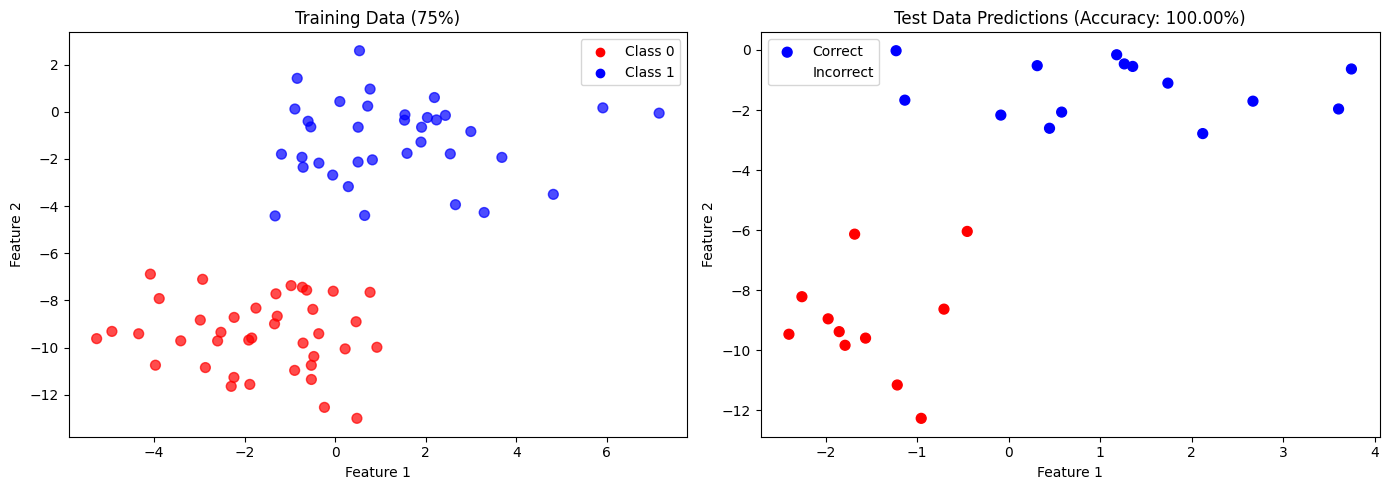


Number of correct predictions: 25
Number of incorrect predictions: 0


In [8]:
# Visualization of blob classification results
# This helps understand how the classifier is working

# Split data again for visualization
X_train, X_test, y_train, y_test = train_test_split(
    X_blob, y_blob, test_size=0.25, random_state=0
)

# Train the model
gnb_viz = GaussianNB()
gnb_viz.fit(X_train, y_train)
y_pred_viz = gnb_viz.predict(X_test)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training data
colors = np.array(["red", "blue"])
axes[0].scatter(X_train[:, 0], X_train[:, 1], c=colors[y_train], s=50, alpha=0.7)
axes[0].set_title("Training Data (75%)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
for label, c in enumerate(colors):
    axes[0].scatter([], [], c=c, label=f"Class {label}")
axes[0].legend()

# Plot 2: Test data with predictions
# Correctly classified points shown as circles, misclassified as X
correct = y_test == y_pred_viz
axes[1].scatter(X_test[correct, 0], X_test[correct, 1], 
                c=colors[y_pred_viz[correct]], s=50, marker='o', label='Correct')
axes[1].scatter(X_test[~correct, 0], X_test[~correct, 1], 
                c=colors[y_pred_viz[~correct]], s=100, marker='x', label='Incorrect')
axes[1].set_title(f"Test Data Predictions (Accuracy: {blob_accuracy:.2%})")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nNumber of correct predictions: {sum(correct)}")
print(f"Number of incorrect predictions: {sum(~correct)}")

#### <div class="alert alert-info">Exercise 2 (plant classification)</div>

Write function `plant_classification` that does the following:

* loads the iris dataset using sklearn (`sklearn.datasets.load_iris`)
* splits the data into training and testing part using the `train_test_split` function so that the training set size is 80% of the whole data (give the call also the `random_state=0` argument to make the result deterministic)
* use Gaussian naive Bayes to fit the training data
* predict labels of the test data
* the function should return the accuracy score of the prediction performance (`sklearn.metrics.accuracy_score`)
<hr/>

**Requirements:**
- Load iris dataset from sklearn
- Split dataset: 80% training, 20% testing with random_state=0
- Use GaussianNB for classification
- Return accuracy score of prediction

**About the Iris Dataset:**
The Iris dataset is a classic dataset in machine learning containing measurements of 150 iris flowers from 3 species (Setosa, Versicolor, Virginica). Each flower has 4 features: sepal length, sepal width, petal length, and petal width.

In [9]:
# Import necessary libraries for Exercise 2
from sklearn.datasets import load_iris           # Load the iris dataset
from sklearn.model_selection import train_test_split  # For splitting data
from sklearn.naive_bayes import GaussianNB       # Gaussian Naive Bayes classifier
from sklearn.metrics import accuracy_score       # For calculating accuracy

In [10]:
def plant_classification():
    """
    Performs Gaussian Naive Bayes classification on the Iris plant dataset.
    
    This function implements a complete machine learning pipeline:
    1. Load data
    2. Split into train/test sets
    3. Train the model
    4. Make predictions
    5. Evaluate performance
    
    The Iris dataset contains 150 samples with 4 features each:
    - Sepal length (cm)
    - Sepal width (cm)
    - Petal length (cm)
    - Petal width (cm)
    
    Classes (3 species of iris flowers):
    - 0: Iris Setosa
    - 1: Iris Versicolor
    - 2: Iris Virginica
    
    Returns:
    --------
    float
        Accuracy score of the prediction (between 0 and 1)
    
    Notes:
    ------
    - Uses 80% of data for training and 20% for testing
    - random_state=0 ensures reproducible results
    - Gaussian NB is efficient and works well with continuous features
    """
    
    # Step 1: Load the Iris dataset
    # This is a classic dataset for classification problems
    iris = load_iris()
    
    # Extract features (X) and labels (y)
    X = iris.data    # Shape: (150, 4) - 150 samples, 4 features
    y = iris.target  # Shape: (150,) - class labels (0, 1, or 2)
    
    # Step 2: Split the dataset into training (80%) and testing (20%) sets
    # random_state=0 ensures reproducibility
    # test_size=0.20 means 20% for testing, leaving 80% for training
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,    # 20% for testing = 80% for training
        random_state=0     # For deterministic results
    )
    
    # Step 3: Initialize and train the Gaussian Naive Bayes classifier
    # GaussianNB computes the mean and variance of each feature for each class
    # It then uses these statistics to calculate class probabilities
    gnb = GaussianNB()
    
    # Fit the model on training data
    # This learns the probability distributions P(features|class)
    gnb.fit(X_train, y_train)
    
    # Step 4: Predict labels for the test set
    # For each test sample, the classifier computes:
    # P(class|features) ∝ P(features|class) * P(class)
    # and assigns the class with highest probability
    y_pred = gnb.predict(X_test)
    
    # Step 5: Calculate accuracy score
    # Accuracy = Number of correct predictions / Total predictions
    accuracy = accuracy_score(y_test, y_pred)
    
    return accuracy

In [11]:
# Test the plant_classification function
plant_accuracy = plant_classification()

# Display results
print("=" * 50)
print("Exercise 2: Plant (Iris) Classification Results")
print("=" * 50)
print(f"Dataset: Iris (150 samples, 4 features, 3 classes)")
print(f"Training set size: 120 samples (80%)")
print(f"Testing set size: 30 samples (20%)")
print(f"\nAccuracy Score: {plant_accuracy:.4f}")
print(f"Accuracy Percentage: {plant_accuracy * 100:.2f}%")
print("=" * 50)

Exercise 2: Plant (Iris) Classification Results
Dataset: Iris (150 samples, 4 features, 3 classes)
Training set size: 120 samples (80%)
Testing set size: 30 samples (20%)

Accuracy Score: 0.9667
Accuracy Percentage: 96.67%


In [12]:
# Detailed analysis of the Iris classification
# This provides additional insights into the model's performance

from sklearn.metrics import classification_report, confusion_matrix

# Load and split data again for detailed analysis
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.20, random_state=0
)

# Train and predict
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

# Display detailed classification report
print("\nDetailed Classification Report:")
print("-" * 50)
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Display confusion matrix
print("\nConfusion Matrix:")
print("-" * 50)
cm = confusion_matrix(y_test, y_pred)
print(f"Rows: Actual classes, Columns: Predicted classes")
print(f"Classes: {list(iris.target_names)}")
print(cm)


Detailed Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       0.93      1.00      0.96        13
   virginica       1.00      0.83      0.91         6

    accuracy                           0.97        30
   macro avg       0.98      0.94      0.96        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
--------------------------------------------------
Rows: Actual classes, Columns: Predicted classes
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
[[11  0  0]
 [ 0 13  0]
 [ 0  1  5]]


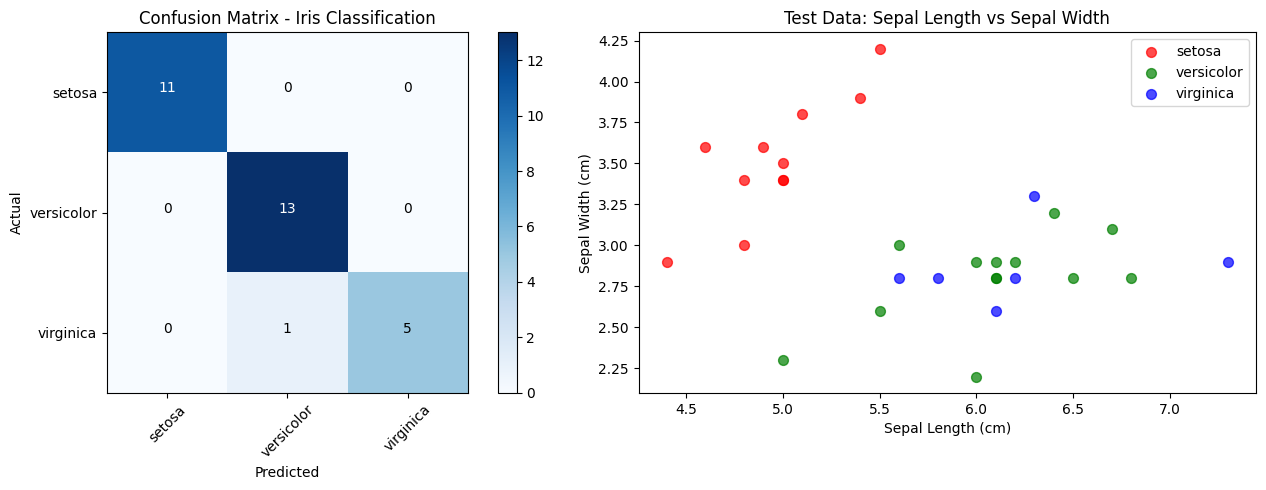

In [13]:
# Visualization of Iris classification
import matplotlib.pyplot as plt
import numpy as np

# Create confusion matrix heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap
im = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title('Confusion Matrix - Iris Classification')
plt.colorbar(im, ax=axes[0])
tick_marks = np.arange(len(iris.target_names))
axes[0].set_xticks(tick_marks)
axes[0].set_xticklabels(iris.target_names, rotation=45)
axes[0].set_yticks(tick_marks)
axes[0].set_yticklabels(iris.target_names)
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Add text annotations to confusion matrix
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, format(cm[i, j], 'd'),
                    horizontalalignment="center",
                    color="white" if cm[i, j] > thresh else "black")

# Plot 2: Feature importance visualization using first two features
# (Sepal length vs Sepal width)
colors = ['red', 'green', 'blue']
for idx, (label, color) in enumerate(zip(iris.target_names, colors)):
    mask = y_test == idx
    axes[1].scatter(X_test[mask, 0], X_test[mask, 1], 
                   c=color, label=label, s=50, alpha=0.7)

axes[1].set_title('Test Data: Sepal Length vs Sepal Width')
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [22]:
# Final Summary - Running both functions
print("=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)

# Exercise 1
X_blob, y_blob = make_blobs(100, 2, centers=2, random_state=2, cluster_std=1.5)
blob_acc = blob_classification(X_blob, y_blob)
print(f"\nExercise 1 - Blob Classification:")
print(f"  Accuracy: {blob_acc:.4f} ({blob_acc*100:.2f}%)")

# Exercise 2
plant_acc = plant_classification()
print(f"\nExercise 2 - Plant (Iris) Classification:")
print(f"  Accuracy: {plant_acc:.4f} ({plant_acc*100:.2f}%)")

print("\n" + "=" * 60)
print("Both exercises completed successfully!")
print("=" * 60)

FINAL RESULTS SUMMARY

Exercise 1 - Blob Classification:
  Accuracy: 1.0000 (100.00%)

Exercise 2 - Plant (Iris) Classification:
  Accuracy: 0.9667 (96.67%)

Both exercises completed successfully!
